In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import h5py
import os
import json

import pickle
import os


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint

from tensorflow.keras.callbacks import EarlyStopping

import matplotlib.pyplot as plt
import numpy as np




import model_architecture as model_arch
import helper

In [12]:
# Dynamic GPU memory allocation: For local prototyping, don't block GPU
config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.compat.v1.Session(config=config)

data_path = 'datasets/2026_04_15_full_pisa_data.h5'

# load data and scalers
x_train, x_test, y_train, y_test, wavelengths = helper.load_data_from_h5(
    data_path,
    condition_name='R',
    input_name='geo',
    save_scalers=True) # Save scalers for first time



#x_train = x_train
#x_test = x_test
#y_train = y_train[:, 35:110]
#y_test = y_test[:, 35:110]

#wavelengths = wavelengths[35:110]

print(wavelengths)
print(wavelengths.shape)

scaler_geo = pickle.load(
    open('{}_scalers.pkl'.format(os.path.splitext(data_path)[0]), 'rb'))

print('x_train shape:', x_train.shape)
print('y_train shape:', y_train.shape)
print('x_test shape:', x_test.shape)
print('y_test shape:', y_test.shape)

[25.    25.025 25.05  25.075 25.1   25.125 25.15  25.175 25.2   25.225
 25.25  25.275 25.3   25.325 25.35  25.375 25.4   25.425 25.45  25.475
 25.5   25.525 25.55  25.575 25.6   25.625 25.65  25.675 25.7   25.725
 25.75  25.775 25.8   25.825 25.85  25.875 25.9   25.925 25.95  25.975
 26.    26.025 26.05  26.075 26.1   26.125 26.15  26.175 26.2   26.225
 26.25  26.275 26.3   26.325 26.35  26.375 26.4   26.425 26.45  26.475
 26.5   26.525 26.55  26.575 26.6   26.625 26.65  26.675 26.7   26.725
 26.75  26.775 26.8   26.825 26.85  26.875 26.9   26.925 26.95  26.975
 27.    27.025 27.05  27.075 27.1   27.125 27.15  27.175 27.2   27.225
 27.25  27.275 27.3   27.325 27.35  27.375 27.4   27.425 27.45  27.475
 27.5   27.525 27.55  27.575 27.6   27.625 27.65  27.675 27.7   27.725
 27.75  27.775 27.8   27.825 27.85  27.875 27.9   27.925 27.95  27.975
 28.    28.025 28.05  28.075 28.1   28.125 28.15  28.175 28.2   28.225
 28.25  28.275 28.3   28.325 28.35  28.375 28.4   28.425 28.45  28.475
 28.5 

2026-07-30 22:37:13.335697: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-07-30 22:37:13.336054: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-07-30 22:37:13.336159: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-07-30 22:37:13.336731: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-07-30 22:37:13.336763: I tensorflow/core/common_runtime/gpu/gpu

In [13]:
keras.backend.clear_session()

# some config for the cVAE
latent_dim = 8   # for interpretability
N_blocks = 1    # Nr of resblocks between upsamplings


# input layers
condition_target_spec_input = keras.layers.Input(
    shape=y_train.shape[1:], name='condition_in')
design_in = keras.Input(shape=x_train.shape[1:], name='design_in')

# spectrum path
x = condition_target_spec_input
x = model_arch.resblock_sequence_down(x, N_filter=32, N_blocks=N_blocks)   # 64 --> 32
x = model_arch.resblock_sequence_down(x, N_filter=64, N_blocks=N_blocks)   # 32 --> 16
x = model_arch.resblock_sequence_down(x, N_filter=128, N_blocks=N_blocks)  # 16 --> 8
x = model_arch.resblock_sequence_down(x, N_filter=256, N_blocks=N_blocks)  # 8 --> 4
x_spec = keras.layers.Flatten()(x)

# geometry path
x = design_in
x = model_arch.resblock_sequence_id(x, N_filter=128, N_blocks=N_blocks)    # 5 --> 2
x_design = keras.layers.Flatten()(x)

# merge both paths
x = keras.layers.Concatenate()([x_spec, x_design])
x = keras.layers.Dense(256)(x)
x = keras.layers.LeakyReLU(alpha=1e-1)(x)

# output: latent sampling
z_mean = keras.layers.Dense(latent_dim)(x)
z_var_log = keras.layers.Dense(latent_dim)(x)
z = model_arch.SamplingRNG()([z_mean, z_var_log])


encoder = keras.Model([design_in, condition_target_spec_input], [
                    z_mean, z_var_log, z], name="encoder")
encoder.summary()

Model: "encoder"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 condition_in (InputLayer)   [(None, 161, 1)]             0         []                            
                                                                                                  
 conv1d_1 (Conv1D)           (None, 161, 32)              32        ['condition_in[0][0]']        
                                                                                                  
 batch_normalization (Batch  (None, 161, 32)              128       ['conv1d_1[0][0]']            
 Normalization)                                                                                   
                                                                                                  
 leaky_re_lu (LeakyReLU)     (None, 161, 32)              0         ['batch_normalization[0]

In [14]:
# condition_target_spec_input
latent_in = keras.Input(shape=(latent_dim,), name='latent_in')

# spectrum path
x = condition_target_spec_input
x = model_arch.resblock_sequence_down(x, N_filter=32, N_blocks=N_blocks)   # 64 --> 32
x = model_arch.resblock_sequence_down(x, N_filter=64, N_blocks=N_blocks)   # 32 --> 16
x = model_arch.resblock_sequence_down(x, N_filter=128, N_blocks=N_blocks)  # 16 --> 8
x = model_arch.resblock_sequence_down(x, N_filter=256, N_blocks=N_blocks)  # 8 --> 4
x_spec = keras.layers.Flatten()(x)

# merge with latent
x = keras.layers.Concatenate()([x_spec, latent_in])

# geometry generator path
x = keras.layers.Dense(6*128)(x)
x = keras.layers.Reshape((6, 128))(x)
x = model_arch.resblock_sequence_id(x, N_filter=128, N_blocks=N_blocks)

# output: number of  channels from design
out_design = keras.layers.Conv1D(
    filters=x_train.shape[-1], kernel_size=1, name='design_out')(x)


decoder = keras.Model(
    [latent_in, condition_target_spec_input],
    out_design, name="decoder")
decoder.summary()
# condition_target_spec_input
latent_in = keras.Input(shape=(latent_dim,), name='latent_in')

# spectrum path
x = condition_target_spec_input
x = model_arch.resblock_sequence_down(x, N_filter=32, N_blocks=N_blocks)   # 64 --> 32
x = model_arch.resblock_sequence_down(x, N_filter=64, N_blocks=N_blocks)   # 32 --> 16
x = model_arch.resblock_sequence_down(x, N_filter=128, N_blocks=N_blocks)  # 16 --> 8
x = model_arch.resblock_sequence_down(x, N_filter=256, N_blocks=N_blocks)  # 8 --> 4
x_spec = keras.layers.Flatten()(x)

# merge with latent
x = keras.layers.Concatenate()([x_spec, latent_in])

# geometry generator path
x = keras.layers.Dense(6*128)(x)
x = keras.layers.Reshape((6, 128))(x)
x = model_arch.resblock_sequence_id(x, N_filter=128, N_blocks=N_blocks)

# output: number of  channels from design
out_design = keras.layers.Conv1D(
    filters=x_train.shape[-1], kernel_size=1, name='design_out')(x)


decoder = keras.Model(
    [latent_in, condition_target_spec_input],
    out_design, name="decoder")
decoder.summary()


Model: "decoder"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 condition_in (InputLayer)   [(None, 161, 1)]             0         []                            
                                                                                                  
 conv1d_37 (Conv1D)          (None, 161, 32)              32        ['condition_in[0][0]']        
                                                                                                  
 batch_normalization_15 (Ba  (None, 161, 32)              128       ['conv1d_37[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 leaky_re_lu_28 (LeakyReLU)  (None, 161, 32)              0         ['batch_normalization_15

In [15]:
z_mean_out, z_var_log_out, z_rnd_out = encoder([design_in, condition_target_spec_input])
design_pred = decoder([z_rnd_out, condition_target_spec_input])   # use randomized latent

cVAE = keras.Model([design_in, condition_target_spec_input], design_pred, name="cVAE")
cVAE.summary()

if not os.path.exists(f"geomerty_cVAE/model_latent{latent_dim}_blocks{N_blocks}/checkpoints/"):
    os.makedirs(f"geomerty_cVAE/model_latent{latent_dim}_blocks{N_blocks}/checkpoints/")


Model: "cVAE"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 design_in (InputLayer)      [(None, 6, 1)]               0         []                            
                                                                                                  
 condition_in (InputLayer)   [(None, 161, 1)]             0         []                            
                                                                                                  
 encoder (Functional)        [(None, 8),                  1953968   ['design_in[0][0]',           
                              (None, 8),                             'condition_in[0][0]']        
                              (None, 8)]                                                          
                                                                                               

In [16]:
input_dim = np.product(x_train.shape[1:])
latent_dim = np.product(z.shape[1:])
beta = 0.001   # weight of KL loss. If too high, reconstruction will suffer.

# print(input_dim)

# --- add multiple losses to the model
# reconstruction loss
reconstruction_loss = keras.losses.mse(keras.backend.flatten(design_in), keras.backend.flatten(design_pred))
cVAE.add_loss(reconstruction_loss)
cVAE.add_metric(reconstruction_loss, name='reconstr_loss', aggregation='mean')

# KL loss
kl_loss = keras.backend.sum(
    1 + z_var_log_out - keras.backend.square(z_mean_out) - keras.backend.exp(z_var_log_out), axis=-1)
kl_loss = beta * keras.backend.mean(-0.5 / latent_dim * kl_loss) # normalize by latent dim to make it more comparable to reconstr loss
cVAE.add_loss(kl_loss)
cVAE.add_metric(kl_loss, name='kl_loss', aggregation='mean')

In [17]:
class PersistentEarlyStopping(EarlyStopping):
    def __init__(self, *args, **kwargs):
        super(PersistentEarlyStopping, self).__init__(*args, **kwargs)
        self.best = np.Inf if self.monitor_op == np.less else -np.Inf
        self.wait = 0
        self._first_run = True

    def on_train_begin(self, logs=None):
        if self._first_run:
            # On the first `fit()` call, reset everything
            self.wait = 0
            self.stopped_epoch = 0
            self.best = np.Inf if self.monitor_op == np.less else -np.Inf
            self._first_run = False


class PersistentReduceLROnPlateau(ReduceLROnPlateau):
    def __init__(self, *args, **kwargs):
        super(PersistentReduceLROnPlateau, self).__init__(*args, **kwargs)
        self._first_run = True

    def on_train_begin(self, logs=None):
        if self._first_run:
            # On the first `fit()` call, run the original setup
            super().on_train_begin(logs)
            self._first_run = False
        else:
            # On subsequent calls, just ensure the LR is correctly set
            # without resetting the counters or the 'best' value.
            self.model.optimizer.lr.assign(self.model.optimizer.lr)

In [18]:
lr = 0.0001

# compile the model
optimizer = keras.optimizers.AdamW(learning_rate=lr)
cVAE.compile(optimizer=optimizer)

# Instantiate your PERSISTENT callbacks ONCE before the loop
reduce_lr = PersistentReduceLROnPlateau(
    monitor='val_loss', factor=0.66, patience=5, verbose=1
)

early_stopping = PersistentEarlyStopping(
    monitor='val_loss', patience=15, verbose=1, restore_best_weights=True
)

hist = None
for i, o in zip([1, 2], [1, 0.5]):
    print(f"\n--- Starting Training Round {i+1} with batch_size={32 * 2**i} ---")
    _h = cVAE.fit(
        x=[x_train, y_train], y=[x_train],
        validation_split=.3,
        batch_size=32 * 2**i,
        epochs=int(25*o), # You can increase epochs per round now
        # Pass the SAME callback objects each time
        callbacks=[reduce_lr, early_stopping]
    )

    # Your history concatenation logic remains the same
    if hist is None:
        hist = _h
    else:
        for k in hist.history:
            hist.history[k] = np.concatenate([hist.history[k], _h.history[k]])

    # Crucially, we must check if early stopping was triggered
    # if cVAE.stop_training:
    #     print(f"Early stopping triggered in round {i+1}. Halting training.")
    #     break

# hist = None
# for i, o in zip([1, 2], [1, 0.5]):
#     print(f"\n--- Starting Training Round {i+1} with batch_size={32 * 2**i} ---")
#     _h = cVAE.fit(
#         x=[x_train, y_train], y=[x_train],
#         validation_split=.3,
#         batch_size=8 * 2**i,
#         epochs=int(50*o), # You can increase epochs per round now
#         # Pass the SAME callback objects each time
#         # callbacks=[reduce_lr, early_stopping]
#     )

#     # Your history concatenation logic remains the same
#     if hist is None:
#         hist = _h
#     else:
#         for k in hist.history:
#             hist.history[k] = np.concatenate([hist.history[k], _h.history[k]])

#     # Crucially, we must check if early stopping was triggered
#     # if cVAE.stop_training:
#     #     print(f"Early stopping triggered in round {i+1}. Halting training.")
#     #     break


--- Starting Training Round 2 with batch_size=64 ---
Epoch 1/25
102/102 [==============================] - 26s 92ms/step - loss: 0.3917 - reconstr_loss: 0.3865 - kl_loss: 0.0053 - val_loss: 0.9229 - val_reconstr_loss: 0.9227 - val_kl_loss: 1.3179e-04 - lr: 1.0000e-04
Epoch 2/25
102/102 [==============================] - 7s 71ms/step - loss: 0.0811 - reconstr_loss: 0.0732 - kl_loss: 0.0079 - val_loss: 0.7822 - val_reconstr_loss: 0.7816 - val_kl_loss: 6.0727e-04 - lr: 1.0000e-04
Epoch 3/25
102/102 [==============================] - 9s 85ms/step - loss: 0.0502 - reconstr_loss: 0.0425 - kl_loss: 0.0077 - val_loss: 0.6283 - val_reconstr_loss: 0.6266 - val_kl_loss: 0.0016 - lr: 1.0000e-04
Epoch 4/25
102/102 [==============================] - 9s 85ms/step - loss: 0.0459 - reconstr_loss: 0.0386 - kl_loss: 0.0072 - val_loss: 0.4223 - val_reconstr_loss: 0.4192 - val_kl_loss: 0.0031 - lr: 1.0000e-04
Epoch 5/25
102/102 [==============================] - 8s 82ms/step - loss: 0.0350 - reconstr_loss

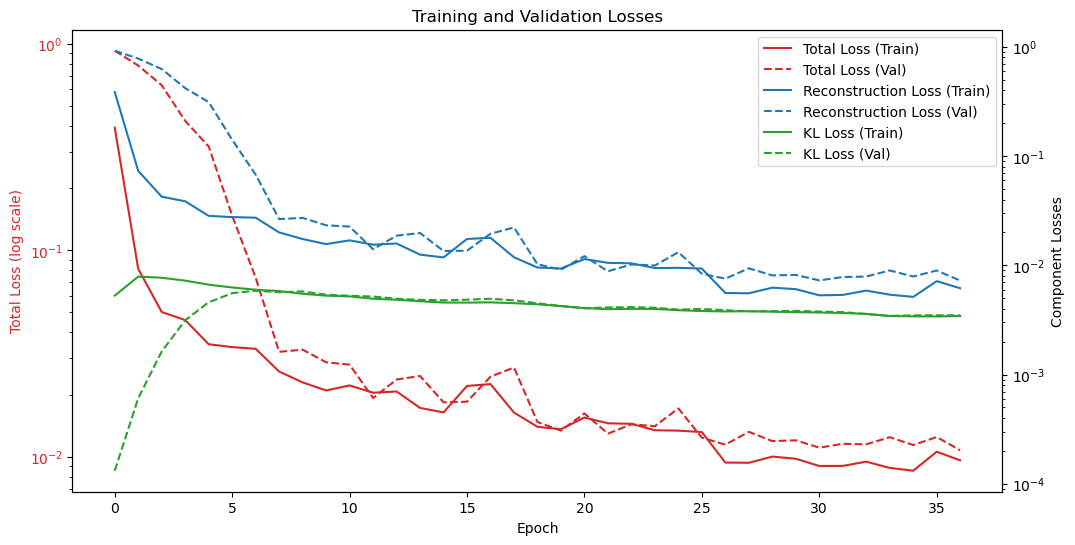

In [20]:
fig, ax1 = plt.subplots(figsize=(12, 6))

#loss_file_out = f'geomerty_cVAE/model_latent{latent_dim}_blocks{N_blocks}/cVAE_spectra_training_losses_latent{latent_dim}_blocks{N_blocks}.json'

# def json_serialize(obj):
#     if isinstance(obj, np.ndarray):
#         return obj.tolist()
#     return obj

# with open(loss_file_out, "w") as f:
#     json.dump(hist.history, f, default=json_serialize)

# Plot total loss on the primary y-axis (ax1)
color = 'tab:red'
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Total Loss (log scale)', color=color)
ax1.plot(hist.history['loss'], color=color, linestyle='-', label='Total Loss (Train)')
ax1.plot(hist.history['val_loss'], color=color, linestyle='--', label='Total Loss (Val)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_yscale('log')

# Create a second y-axis (ax2) that shares the same x-axis
ax2 = ax1.twinx()
ax2.set_ylabel('Component Losses')

ax2.set_yscale('log')

# Plot reconstruction loss on the secondary y-axis
color_recon = 'tab:blue'
ax2.plot(hist.history['reconstr_loss'], color=color_recon, linestyle='-', label='Reconstruction Loss (Train)')
ax2.plot(hist.history['val_reconstr_loss'], color=color_recon, linestyle='--', label='Reconstruction Loss (Val)')

# Plot KL loss on the secondary y-axis
color_kl = 'tab:green'
ax2.plot(hist.history['kl_loss'], color=color_kl, linestyle='-', label='KL Loss (Train)')
ax2.plot(hist.history['val_kl_loss'], color=color_kl, linestyle='--', label='KL Loss (Val)')
ax2.tick_params(axis='y')

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='best')

plt.title('Training and Validation Losses')
plt.savefig(f'geomerty_cVAE/model_latent{latent_dim}_blocks{N_blocks}/cVAE_geomerty_training_losses_latent{latent_dim}_blocks{N_blocks}.png')
plt.show()

In [4]:
model_name_suffix = f'latent{latent_dim}_blocks{N_blocks}'
cVAE.save(f'geomerty_cVAE_reduced_range_2/model_latent{latent_dim}_blocks{N_blocks}/full_model_cVAE_geomerty_{model_name_suffix}.h5')
encoder.save(f'geomerty_cVAE_reduced_range_2/model_latent{latent_dim}_blocks{N_blocks}/encoder_cVAE_geomerty_encoder_{model_name_suffix}.h5')
decoder.save(f'geomerty_cVAE_reduced_range_2/model_latent{latent_dim}_blocks{N_blocks}/decoder_cVAE_geomerty_decoder_{model_name_suffix}.h5')


NameError: name 'latent_dim' is not defined

In [10]:
try:
    from sklearn.decomposition import PCA
    HAS_SKLEARN = True
except ImportError:
    HAS_SKLEARN = False

try:
    import umap
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False

def visualize_latent_space(model, x_data, y_data, batch_size=32, num_batches=20, method='umap', color_by='y_first', x_col_idx=0, scaler_geo=None, save_path=None, full_model=None):
    """
    Plots the latent space colored by a specified metric from x_data or y_data.
    Supports dimensionality reduction via 'umap' or 'pca'.
    
    Args:
        model: A Keras model representing the Conditional VAE.
        x_data: NumPy array of input data (e.g., x_test, shape: [N, 6, 1]).
        y_data: NumPy array of condition data (e.g., y_test, shape: [N, 161, 1]).
        batch_size: Number of samples per batch.
        num_batches: The maximum number of batches to process.
        method: Dimensionality reduction method ('umap' or 'pca').
        color_by: String dictating color mapping ('y_first', 'y_avg', 'x_col', or 'mse').
        x_col_idx: Integer specifying which x_data column to use if color_by='x_col'.
        scaler_geo: Optional scaler object with an `inverse_transform` method to convert x_data back to physical units.
        save_path: Optional path to save the generated plot.
        full_model: The complete cVAE model, required if color_by='mse'.
    """
    latents = []
    condition_vals = [] # Track the chosen variable to color the plot
    
    if color_by == 'y_first':
        color_label = "Condition (y) Feature 0"
        title_suffix = "y Feature 0"
    elif color_by == 'y_avg':
        color_label = "Condition (y) Average"
        title_suffix = "y Average"
    elif color_by == 'x_col':
        color_label = f"Design (x) Col {x_col_idx}" + (" (Physical Units)" if scaler_geo else "")
        title_suffix = f"x Col {x_col_idx}"
    elif color_by == 'mse':
        if full_model is None:
            raise ValueError("full_model must be provided if color_by='mse'")
        color_label = "Reconstruction MSE"
        title_suffix = "Reconstruction MSE"
    else:
        raise ValueError("color_by must be 'y_first', 'y_avg', 'x_col', or 'mse'")
    
    print("Extracting latent representations...")
    
    # Calculate how many batches we can actually process
    total_samples = len(x_data)
    max_possible_batches = int(np.ceil(total_samples / batch_size))
    actual_batches = min(num_batches, max_possible_batches)
    
    # Iterate over the numpy arrays in batches
    for i in range(actual_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, total_samples)
        
        batch_data = x_data[start_idx:end_idx]
        batch_condition = y_data[start_idx:end_idx]
            
        # In Keras, models handle device placement internally most of the time,
        # especially if you are just passing tensors.
        # Ensure your encode method handles training=False if 0it has layers like Dropout/BatchNorm
        # Convert numpy arrays to tensors to be safe, though Keras often handles this automatically
        batch_data_tf = tf.convert_to_tensor(batch_data, dtype=tf.float32)
        batch_condition_tf = tf.convert_to_tensor(batch_condition, dtype=tf.float32)
        
        # Call the encoder directly using the standard __call__ method since it's a keras.Model
        # Pass the inputs as a list to match the [design_in, condition_target_spec_input] definition
        encode_outputs = model([batch_data_tf, batch_condition_tf], training=False)
        
        # Unpack based on your encoder definition: [z_mean, z_var_log, z]
        mu = encode_outputs[0]
            
        latents.append(mu.numpy())
        
        if color_by == 'y_first':
            # Grab the 0th feature of the condition sequence (first element)
            condition_vals.append(batch_condition[:, 0, 0])
        elif color_by == 'y_avg':
            # Average across the sequence length (axis 1) and features (axis 2)
            condition_vals.append(np.mean(batch_condition, axis=(1, 2)))
        elif color_by == 'x_col':
            if scaler_geo is not None:
                # Reshape to 2D (batch_size, num_features) for the scaler
                batch_data_2d = batch_data[:, :, 0]
                batch_physical = scaler_geo.inverse_transform(batch_data_2d)
                condition_vals.append(batch_physical[:, x_col_idx])
            else:
                # Grab the specific column from the scaled input design data
                condition_vals.append(batch_data[:, x_col_idx, 0])
        elif color_by == 'mse':
            # Generate reconstructed designs using the full cVAE model
            reconstructed = full_model([batch_data_tf, batch_condition_tf], training=False)
            # Calculate Mean Squared Error per sample
            mse = np.mean(np.square(batch_data - reconstructed.numpy()), axis=tuple(range(1, batch_data.ndim)))
            condition_vals.append(mse)
        
    latents = np.concatenate(latents, axis=0)
    condition_vals = np.concatenate(condition_vals, axis=0)
    
    # Dimensionality Reduction if latent_dim > 2
    if latents.shape[1] > 2:
        if method == 'umap' and HAS_UMAP:
            print("Running UMAP on latent space...")
            reducer = umap.UMAP(random_state=42)
            latents_2d = reducer.fit_transform(latents)
            title_prefix = "UMAP of "
        elif HAS_SKLEARN:
            print("Running PCA on latent space...")
            pca = PCA(n_components=2)
            latents_2d = pca.fit_transform(latents)
            title_prefix = "PCA of "
        else:
            latents_2d = latents[:, :2]
            title_prefix = "First 2 Dims of "
    else:
        latents_2d = latents
        title_prefix = ""
        
    import matplotlib.colors as mcolors
    norm = mcolors.LogNorm() if True else None

    plt.figure(figsize=(9, 7))
    scatter = plt.scatter(latents_2d[:, 0], latents_2d[:, 1], c=condition_vals, cmap='Blues', alpha=1, s=20, norm=norm)
    plt.colorbar(scatter, label=color_label)
    plt.title(f"{title_prefix}cVAE Latent Space (Colored by {title_suffix})")
    plt.xlabel(f"{method.upper()} 1" if method in ['umap', 'pca'] else "Latent Dim 1")
    plt.ylabel(f"{method.upper()} 2" if method in ['umap', 'pca'] else "Latent Dim 2")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path)
        print(f"--- Latent space plot saved to {save_path} ---")
        
    plt.show()
    plt.close()

Extracting latent representations...
Running PCA on latent space...


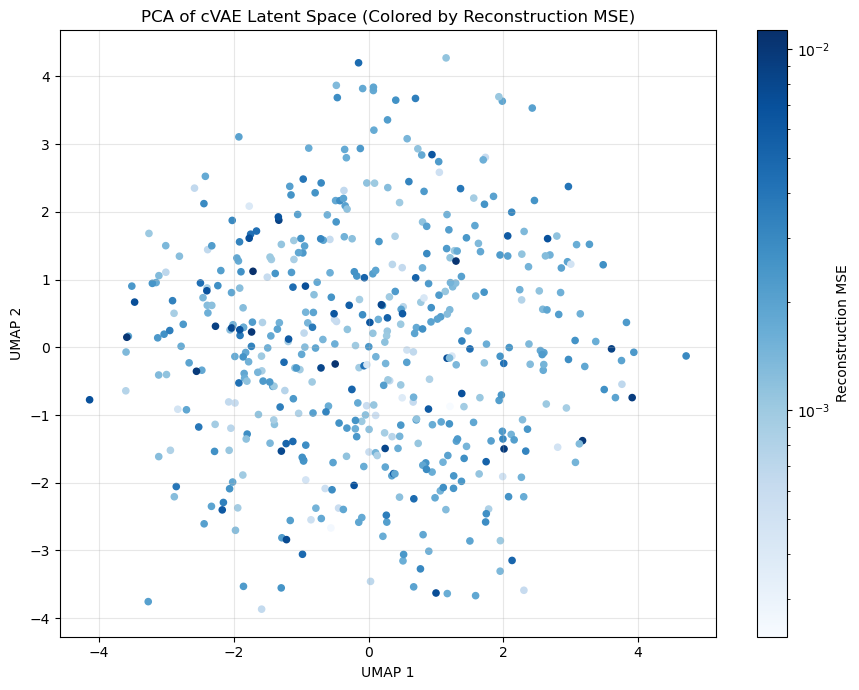

In [11]:
visualize_latent_space(encoder, x_test, y_test, color_by='mse', scaler_geo=scaler_geo, full_model=cVAE)

In [12]:
from matplotlib.collections import EllipseCollection

def visualize_latent_space(model, x_data, y_data, batch_size=32, num_batches=20, method='umap', color_by='y_first', x_col_idx=0, scaler_geo=None, save_path=None, plot_ellipses=False):
    """
    Plots the latent space colored by a specified metric from x_data or y_data.
    Supports dimensionality reduction via 'umap' or 'pca'.
    
    Args:
        model: A Keras model representing the Conditional VAE.
        x_data: NumPy array of input data (e.g., x_test, shape: [N, 6, 1]).
        y_data: NumPy array of condition data (e.g., y_test, shape: [N, 161, 1]).
        batch_size: Number of samples per batch.
        num_batches: The maximum number of batches to process.
        method: Dimensionality reduction method ('umap' or 'pca').
        color_by: String dictating color mapping ('y_first', 'y_avg', or 'x_col').
        x_col_idx: Integer specifying which x_data column to use if color_by='x_col'.
        scaler_geo: Optional scaler object with an `inverse_transform` method.
        save_path: Optional path to save the generated plot.
        plot_ellipses: Boolean, if True plots 1-std-dev Gaussian ovals using z_var_log.
    """
    latents = []
    log_vars = []
    condition_vals = [] # Track the chosen variable to color the plot
    
    if color_by == 'y_first':
        color_label = "Condition (y) Feature 0"
        title_suffix = "y Feature 0"
    elif color_by == 'y_avg':
        color_label = "Condition (y) Average"
        title_suffix = "y Average"
    elif color_by == 'x_col':
        color_label = f"Design (x) Col {x_col_idx}" + (" (Physical Units)" if scaler_geo else "")
        title_suffix = f"x Col {x_col_idx}"
    else:
        raise ValueError("color_by must be 'y_first', 'y_avg', or 'x_col'")
    
    print("Extracting latent representations...")
    
    # Calculate how many batches we can actually process
    total_samples = len(x_data)
    max_possible_batches = int(np.ceil(total_samples / batch_size))
    actual_batches = min(num_batches, max_possible_batches)
    
    # Iterate over the numpy arrays in batches
    for i in range(actual_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, total_samples)
        
        batch_data = x_data[start_idx:end_idx]
        batch_condition = y_data[start_idx:end_idx]
            
        # In Keras, models handle device placement internally most of the time,
        # especially if you are just passing tensors.
        # Ensure your encode method handles training=False if it has layers like Dropout/BatchNorm
        # Convert numpy arrays to tensors to be safe, though Keras often handles this automatically
        batch_data_tf = tf.convert_to_tensor(batch_data, dtype=tf.float32)
        batch_condition_tf = tf.convert_to_tensor(batch_condition, dtype=tf.float32)
        
        # Call the encoder directly using the standard __call__ method since it's a keras.Model
        # Pass the inputs as a list to match the [design_in, condition_target_spec_input] definition
        encode_outputs = model([batch_data_tf, batch_condition_tf], training=False)
        
        # Unpack based on your encoder definition: [z_mean, z_var_log, z]
        mu = encode_outputs[0]
        log_var = encode_outputs[1]
            
        latents.append(mu.numpy())
        log_vars.append(log_var.numpy())
        
        if color_by == 'y_first':
            # Grab the 0th feature of the condition sequence (first element)
            condition_vals.append(batch_condition[:, 0, 0])
        elif color_by == 'y_avg':
            # Average across the sequence length (axis 1) and features (axis 2)
            condition_vals.append(np.mean(batch_condition, axis=(1, 2)))
        elif color_by == 'x_col':
            if scaler_geo is not None:
                # Reshape to 2D (batch_size, num_features) for the scaler
                batch_data_2d = batch_data[:, :, 0]
                batch_physical = scaler_geo.inverse_transform(batch_data_2d)
                condition_vals.append(batch_physical[:, x_col_idx])
            else:
                # Grab the specific column from the scaled input design data
                condition_vals.append(batch_data[:, x_col_idx, 0])
        
    latents = np.concatenate(latents, axis=0)
    log_vars = np.concatenate(log_vars, axis=0)
    condition_vals = np.concatenate(condition_vals, axis=0)
    
    # Check if we need to override dimension reduction for valid ellipses
    if plot_ellipses and latents.shape[1] > 2 and method in ['umap', 'pca']:
        print(f"Note: Gaussian ellipses cannot be accurately scaled through {method.upper()}. "
              "Defaulting to raw Latent Dims 0 and 1 for accurate variance visualization.")
        method = 'raw'

    # Dimensionality Reduction if latent_dim > 2
    if latents.shape[1] > 2 and method != 'raw':
        if method == 'umap' and HAS_UMAP:
            print("Running UMAP on latent space...")
            reducer = umap.UMAP(random_state=42)
            latents_2d = reducer.fit_transform(latents)
            title_prefix = "UMAP of "
        elif method == 'pca' and HAS_SKLEARN:
            print("Running PCA on latent space...")
            pca = PCA(n_components=2)
            latents_2d = pca.fit_transform(latents)
            title_prefix = "PCA of "
        else:
            latents_2d = latents[:, :2]
            title_prefix = "First 2 Dims of "
    else:
        latents_2d = latents[:, :2] if latents.shape[1] >= 2 else latents
        title_prefix = "First 2 Dims of " if method == 'raw' else ""
        
    plt.figure(figsize=(9, 7))
    ax = plt.gca()
    
    scatter = ax.scatter(latents_2d[:, 0], latents_2d[:, 1], c=condition_vals, cmap='viridis', alpha=0.9, s=20, zorder=2)
    
    if plot_ellipses:
        print("Plotting Gaussian ovals (1 standard deviation)...")
        # Convert log-variance to standard deviation: sigma = exp(0.5 * log_var)
        stds = np.exp(0.5 * log_vars)
        # Width/height of the ellipse for 1 std dev is 2 * sigma
        widths = 2 * stds[:, 0]
        heights = 2 * stds[:, 1]
        angles = np.zeros_like(widths) # Assuming diagonal covariance (0 rotation)
        
        ec = EllipseCollection(
            widths=widths,
            heights=heights,
            angles=angles,
            units='x',
            offsets=latents_2d,
            transOffset=ax.transData,
            cmap='viridis',
            norm=scatter.norm,
            zorder=1
        )
        ec.set_array(condition_vals)
        ec.set_alpha(0.15) # Keep them transparent so points are visible
        ax.add_collection(ec)

    plt.colorbar(scatter, label=color_label)
    plt.title(f"{title_prefix}cVAE Latent Space (Colored by {title_suffix})")
    plt.xlabel(f"{method.upper()} 1" if method in ['umap', 'pca'] else "Latent Dim 1")
    plt.ylabel(f"{method.upper()} 2" if method in ['umap', 'pca'] else "Latent Dim 2")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path)
        print(f"--- Latent space plot saved to {save_path} ---")
        
    plt.show()
    plt.close()

Extracting latent representations...
Note: Gaussian ellipses cannot be accurately scaled through UMAP. Defaulting to raw Latent Dims 0 and 1 for accurate variance visualization.
Plotting Gaussian ovals (1 standard deviation)...


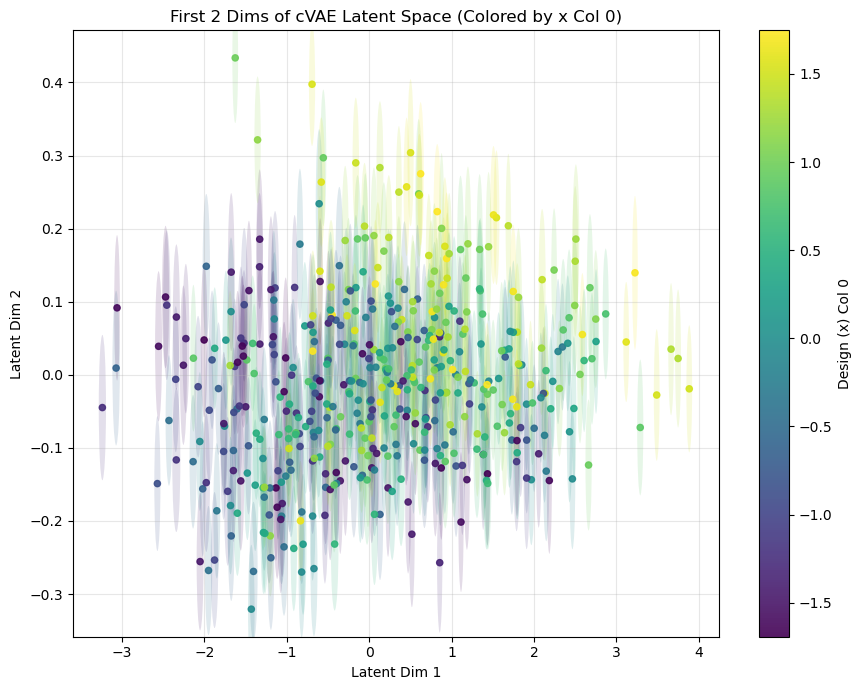

In [13]:
visualize_latent_space(encoder, x_test, y_test, color_by='x_col', x_col_idx=0, plot_ellipses=True)

In [14]:
def visualize_latent_space_with_highlights(model, x_data, y_data, N=5, batch_size=32, num_batches=20, method='umap', color_by='y_first', x_col_idx=0, scaler_geo=None, save_path=None):
    """
    Plots the latent space colored by a specified metric, and highlights N randomly selected 
    examples from the dataset with distinct markers and labels.
    
    Args:
        model: A Keras model representing the Conditional VAE encoder.
        x_data: NumPy array of input data.
        y_data: NumPy array of condition data.
        N: Number of examples to randomly sample and highlight.
        batch_size: Number of samples per batch for latent extraction.
        num_batches: Maximum number of batches to process for the background plot.
        method: Dimensionality reduction method ('umap' or 'pca').
        color_by: String dictating color mapping ('y_first', 'y_avg', or 'x_col').
        x_col_idx: Integer specifying which x_data column to use if color_by='x_col'.
        scaler_geo: Optional scaler object to convert x_data back to physical units.
        save_path: Optional path to save the generated plot.
    """
    latents = []
    condition_vals = []
    
    if color_by == 'y_first':
        color_label = "Condition (y) Feature 0"
        title_suffix = "y Feature 0"
    elif color_by == 'y_avg':
        color_label = "Condition (y) Average"
        title_suffix = "y Average"
    elif color_by == 'x_col':
        color_label = f"Design (x) Col {x_col_idx}" + (" (Physical Units)" if scaler_geo else "")
        title_suffix = f"x Col {x_col_idx}"
    else:
        raise ValueError("color_by must be 'y_first', 'y_avg', or 'x_col'")
    
    print("Extracting latent representations for background...")
    
    total_samples = len(x_data)
    max_possible_batches = int(np.ceil(total_samples / batch_size))
    actual_batches = min(num_batches, max_possible_batches)
    processed_samples = actual_batches * batch_size
    
    # Ensure N isn't larger than the number of samples we are plotting
    N = min(N, processed_samples)
    
    for i in range(actual_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, total_samples)
        
        batch_data = x_data[start_idx:end_idx]
        batch_condition = y_data[start_idx:end_idx]
            
        batch_data_tf = tf.convert_to_tensor(batch_data, dtype=tf.float32)
        batch_condition_tf = tf.convert_to_tensor(batch_condition, dtype=tf.float32)
        
        encode_outputs = model([batch_data_tf, batch_condition_tf], training=False)
        mu = encode_outputs[0]
            
        latents.append(mu.numpy())
        
        if color_by == 'y_first':
            condition_vals.append(batch_condition[:, 0, 0])
        elif color_by == 'y_avg':
            condition_vals.append(np.mean(batch_condition, axis=(1, 2)))
        elif color_by == 'x_col':
            if scaler_geo is not None:
                batch_data_2d = batch_data[:, :, 0]
                batch_physical = scaler_geo.inverse_transform(batch_data_2d)
                condition_vals.append(batch_physical[:, x_col_idx])
            else:
                condition_vals.append(batch_data[:, x_col_idx, 0])
        
    latents = np.concatenate(latents, axis=0)
    condition_vals = np.concatenate(condition_vals, axis=0)
    
    # We select indices from the subset of data we actually processed
    highlight_indices = np.random.choice(len(latents), size=N, replace=False)
    
    reducer_obj = None # Keep track of the reducer to project new points if needed
    
    if latents.shape[1] > 2:
        if method == 'umap' and HAS_UMAP:
            print("Running UMAP on latent space...")
            reducer_obj = umap.UMAP(random_state=42)
            latents_2d = reducer_obj.fit_transform(latents)
            title_prefix = "UMAP of "
        elif HAS_SKLEARN:
            print("Running PCA on latent space...")
            reducer_obj = PCA(n_components=2)
            latents_2d = reducer_obj.fit_transform(latents)
            title_prefix = "PCA of "
        else:
            latents_2d = latents[:, :2]
            title_prefix = "First 2 Dims of "
    else:
        latents_2d = latents
        title_prefix = ""
        
    plt.figure(figsize=(10, 8))
    
    # Plot the background points
    scatter = plt.scatter(latents_2d[:, 0], latents_2d[:, 1], c=condition_vals, cmap='viridis', alpha=0.5, s=20)
    plt.colorbar(scatter, label=color_label)
    
    # Highlight the N selected points
    highlight_colors = plt.cm.rainbow(np.linspace(0, 1, N))
    
    for i, idx in enumerate(highlight_indices):
        x_val = latents_2d[idx, 0]
        y_val = latents_2d[idx, 1]
        
        # Plot a larger, distinct marker with an edge
        plt.scatter(x_val, y_val, color=highlight_colors[i], marker='o', s=100, edgecolor='black', linewidth=1.5, zorder=5, label=f'Sample {idx}')
        
        # Add a text label next to the marker
        plt.annotate(f'S{idx}', (x_val, y_val), xytext=(5, 5), textcoords='offset points', 
                     fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8), zorder=6)

    plt.title(f"{title_prefix}cVAE Latent Space with {N} Highlighted Samples\n(Background Colored by {title_suffix})")
    plt.xlabel(f"{method.upper()} 1" if method in ['umap', 'pca'] else "Latent Dim 1")
    plt.ylabel(f"{method.upper()} 2" if method in ['umap', 'pca'] else "Latent Dim 2")
    
    # Add a legend for the highlighted points
    if N > 0:
        plt.legend()

    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
        print(f"--- Latent space plot saved to {save_path} ---")
        
    plt.show()
    plt.close()
    
    return highlight_indices, latents_2d, condition_vals 

In [15]:
# keras.backend.clear_session()

model_folder = "geomerty_cVAE_reduced_range_2/model_latent8_blocks1/"

# encoder_file = os.path.join(model_folder, "encoder_cVAE_geomerty_encoder_latent8_blocks1.h5")

# # load trained encoder
# encoder = keras.models.load_model(encoder_file)

Extracting latent representations for background...
Running PCA on latent space...


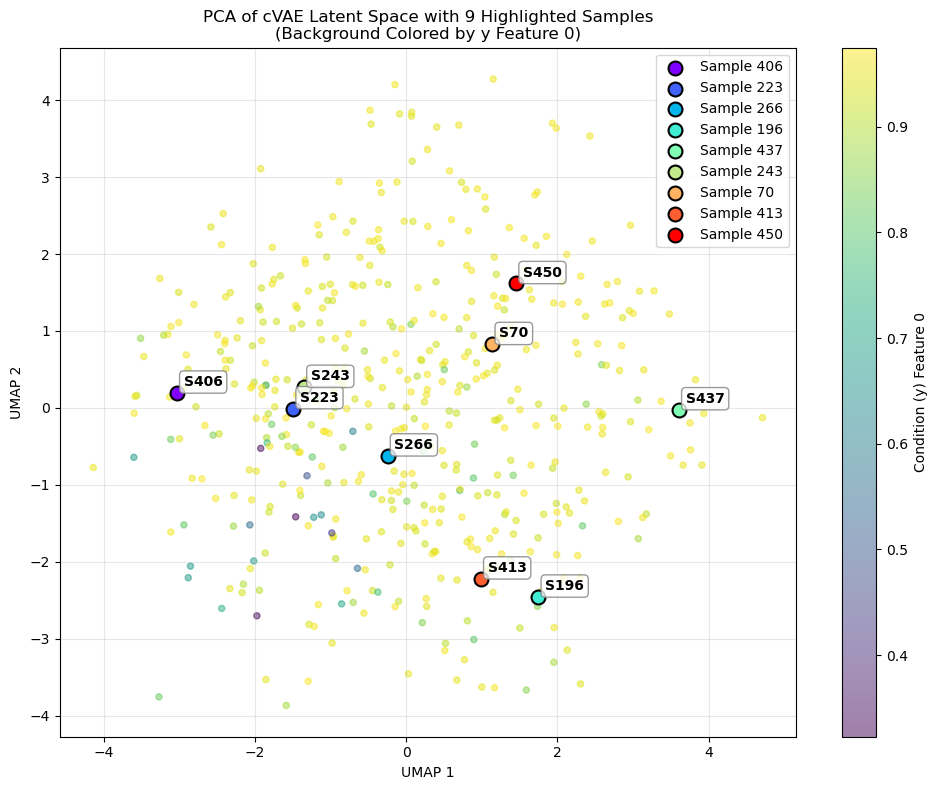

In [16]:
samples, latents_2d, condition_vals = visualize_latent_space_with_highlights(encoder, x_test, y_test, N = 9)

In [19]:
print(latents_2d.shape)
print(y_test.squeeze().shape)
print(x_test.squeeze().shape)

print(x_test[0])
print(scaler_geo.inverse_transform(x_test.squeeze())[0])
print(y_test.squeeze()[0])

model_folder = f"geomerty_cVAE_reduced_range_2/model_latent{latent_dim}_blocks{N_blocks}/"

np.savetxt(f'{model_folder}latents_2d.csv', latents_2d, delimiter=',', header='Latent_Dim_1,Latent_Dim_2', comments='#')

np.savetxt(f'{model_folder}test_condition.csv', y_test.squeeze(), delimiter=',')
header = 'h_pill, d_pill, w_pill, d_sep, w_sep, angle\num, um, um, um, um, rad'
np.savetxt(f'{model_folder}test_input.csv', scaler_geo.inverse_transform(x_test.squeeze()), delimiter=',', header=header, comments='#')

(490, 2)
(490, 75)
(490, 6)
[[-0.4978606 ]
 [ 0.7946986 ]
 [-0.65526396]
 [ 1.2744253 ]
 [-0.70609456]
 [-1.4652354 ]]
[0.67436254 1.5978571  0.97906405 1.7788796  0.79857874 0.0775378 ]
[0.958261   0.9575508  0.9567755  0.95592743 0.9549978  0.9539762
 0.95285034 0.95160556 0.95022416 0.94868475 0.9469612  0.9450213
 0.94282424 0.9403188  0.9374388  0.93409735 0.93017864 0.92552394
 0.9199107  0.91301644 0.90435773 0.8931842  0.8783113  0.8579975
 0.83071464 0.7983777  0.76311225 0.7136991  0.63603145 0.5269335
 0.415118   0.3737669  0.4280867  0.5165937  0.60124755 0.6658665
 0.7029908  0.7148986  0.7061699  0.6881554  0.6801106  0.6778883
 0.66388434 0.63496476 0.59145683 0.52863896 0.44277474 0.33383468
 0.20909925 0.08990509 0.01240661 0.00861021 0.07772917 0.18747944
 0.3046022  0.40805942 0.48746794 0.5400298  0.565023   0.56154895
 0.5345624  0.50785315 0.5037643  0.5053381  0.48505366 0.42767787
 0.3463178  0.28898767 0.3068209  0.39206943 0.49269265 0.5743401
 0.63401604 0.67

In [22]:
def save_inference(inference_id, inference_params, inference_output, target, target_id, wavelengths, scaler_geo, base_dir="inference_data"):
    """Logs the inference run and saves results using the unified ID."""
    results_dir = os.path.join(base_dir, "results")
    os.makedirs(results_dir, exist_ok=True)

    # Find the highest existing run ID and increment it
    existing_runs = [
        int(d.replace('run_', '')) for d in os.listdir(results_dir)
        if d.startswith('run_') and d.replace('run_', '').isdigit()
    ]
    run_id = max(existing_runs) + 1 if existing_runs else 1

    run_folder = os.path.join(results_dir, f"run_{run_id}")
    run_folder = os.path.join(results_dir, f"run_{inference_id}")
    os.makedirs(run_folder, exist_ok=True)

    designs_predict_physical = scaler_geo.inverse_transform(inference_output)

    print("\n--- Physical Designs ---")
    print(designs_predict_physical)

    target = np.expand_dims(target, axis=1)
    wavelengths_cut = np.expand_dims(wavelengths, axis=1)
    target_spectra = np.hstack((wavelengths_cut, target))

    print(f"Saving predicted designs with full run ID: {run_id}")
    print(f"Saving predicted designs with full inference ID: {inference_id}")

    np.savetxt(os.path.join(run_folder, f'{inference_id}_suggested_designs.csv'), inference_output, delimiter=',')
    np.savetxt(os.path.join(run_folder, f'{inference_id}_suggested_designs_physical.csv'), designs_predict_physical, delimiter=',')
    np.savetxt(os.path.join(run_folder, f'{inference_id}_target_spectra.csv'), target_spectra , delimiter=',')

    header = 'h_pill, d_pill, w_pill, d_sep, w_sep, angle\num, um, um, um, um, rad'
    np.savetxt(os.path.join(run_folder, f'{inference_id}_params.csv'), designs_predict_physical, delimiter=',', header=header, comments='')

    metadata = {
        "inference_run_id": inference_id,
        "target_id": target_id,
        "inference_params": inference_params
    }

    with open(os.path.join(run_folder, f'{inference_id}_metadata.json'), 'w') as f:
        json.dump(metadata, f, indent=4)

    print(f"Data saved in: {run_folder}")
    return run_id

In [23]:
def make_infrerence(decoder, z_sample, condition_vector):
    """Generates designs from the decoder given latent samples and condition vectors."""
    condition_vector_tf = tf.expand_dims(tf.convert_to_tensor(condition_vector),1)
    condition_vector_tf = tf.repeat(tf.expand_dims(condition_vector_tf, axis=0), repeats=z_sample.shape[0], axis=0)

    decoder_in = [z_sample, condition_vector_tf]
    designs_predict = tf.squeeze(decoder.predict(decoder_in, verbose=0))
    return designs_predict



--- Physical Designs ---
[[0.6892962  1.610748   0.90334576 0.6014427  1.4925336  0.26392087]
 [0.9120392  1.2749968  1.4426552  1.3336726  1.1935287  0.32915384]
 [0.713117   0.9243649  1.0086429  1.1657888  0.99918085 0.662189  ]
 [0.86841357 1.8415531  1.5049207  1.6855284  1.118343   0.30477434]
 [0.66652507 0.53364617 1.4179842  1.064328   0.96248823 0.41995782]]
Saving predicted designs with full run ID: 1
Saving predicted designs with full inference ID: 12121406
Data saved in: geomerty_cVAE_reduced_range_2/inference_data/results/run_12121406


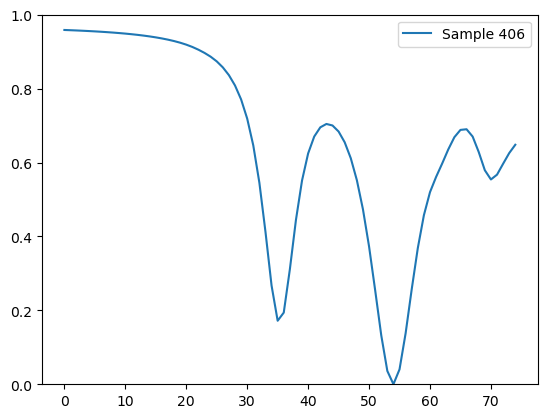


--- Physical Designs ---
[[0.73744726 1.6714315  0.93135023 0.5419326  1.4312223  0.24602614]
 [0.9537276  1.3350672  1.4760262  1.2624571  1.1356283  0.31357554]
 [0.76105297 0.98323786 1.0436399  1.0996296  0.9367348  0.6444476 ]
 [0.91340846 1.8990407  1.535363   1.6197474  1.0557866  0.28978446]
 [0.7076379  0.60049534 1.4451216  0.98944074 0.9060086  0.4103804 ]]
Saving predicted designs with full run ID: 12121407
Saving predicted designs with full inference ID: 12121223
Data saved in: geomerty_cVAE_reduced_range_2/inference_data/results/run_12121223


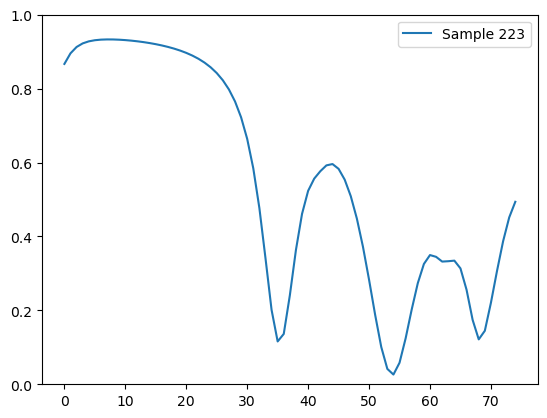


--- Physical Designs ---
[[0.72201586 1.6276196  1.0900586  0.5744569  1.3873817  0.25234076]
 [0.939202   1.2876493  1.6227193  1.3037566  1.0854664  0.31824097]
 [0.74682075 0.9462498  1.1898242  1.1366844  0.89140403 0.64582205]
 [0.89776397 1.8493592  1.6881777  1.6538782  1.0051157  0.2918182 ]
 [0.697715   0.5629844  1.5712036  1.0228586  0.86188596 0.41162357]]
Saving predicted designs with full run ID: 12121407
Saving predicted designs with full inference ID: 12121266
Data saved in: geomerty_cVAE_reduced_range_2/inference_data/results/run_12121266


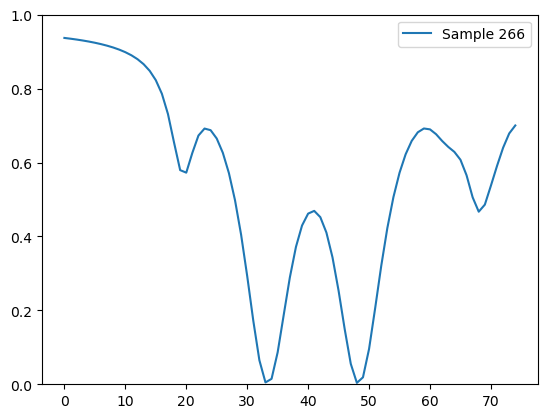


--- Physical Designs ---
[[0.7264566  1.5539646  1.1550399  0.57913774 1.3265536  0.24909277]
 [0.9500002  1.184503   1.7430193  1.3166412  0.97989625 0.30194902]
 [0.7509987  0.8430919  1.2846618  1.1398602  0.81632656 0.6388861 ]
 [0.907881   1.7764177  1.7999003  1.6704903  0.8918441  0.27784392]
 [0.7055379  0.45629612 1.6558676  1.0373144  0.7569661  0.39877275]]
Saving predicted designs with full run ID: 12121407
Saving predicted designs with full inference ID: 12121196
Data saved in: geomerty_cVAE_reduced_range_2/inference_data/results/run_12121196


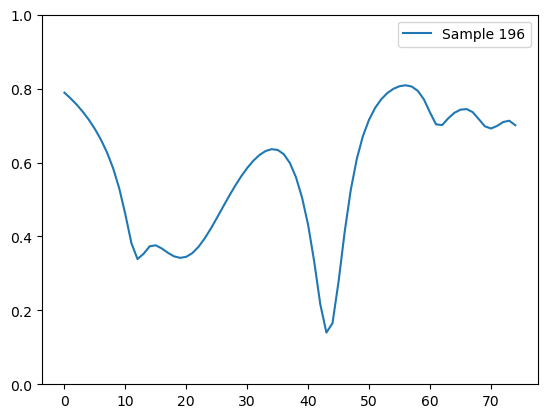


--- Physical Designs ---
[[0.6597016  1.6068767  0.8258137  0.63332707 1.555724   0.27317128]
 [0.887918   1.2755718  1.3658587  1.3607794  1.2548584  0.33677453]
 [0.6839492  0.91935587 0.92485857 1.1956996  1.0681554  0.6716659 ]
 [0.84217787 1.8427824  1.4244853  1.7106003  1.1787887  0.3092507 ]
 [0.6370536  0.52892196 1.348614   1.0936741  1.022878   0.42945555]]
Saving predicted designs with full run ID: 12121407
Saving predicted designs with full inference ID: 12121437
Data saved in: geomerty_cVAE_reduced_range_2/inference_data/results/run_12121437


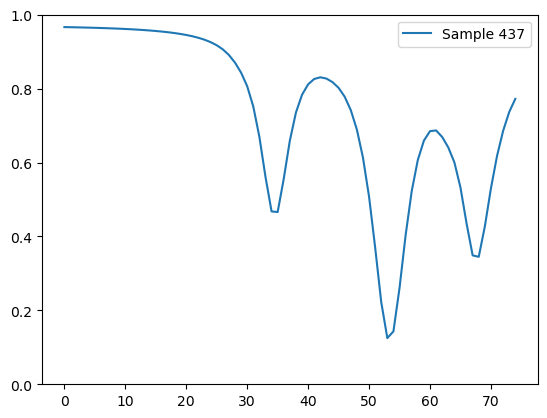


--- Physical Designs ---
[[0.7341298  1.6521764  1.0585124  0.55186254 1.390224   0.2474047 ]
 [0.9503707  1.3151685  1.593808   1.2806724  1.0941254  0.3158634 ]
 [0.7580376  0.9710592  1.1605309  1.1138824  0.8965096  0.6447544 ]
 [0.90933025 1.8763824  1.6591051  1.6320382  1.0131665  0.29036397]
 [0.7073803  0.5865166  1.54771    0.9999552  0.8668563  0.40991974]]
Saving predicted designs with full run ID: 12121438
Saving predicted designs with full inference ID: 12121243
Data saved in: geomerty_cVAE_reduced_range_2/inference_data/results/run_12121243


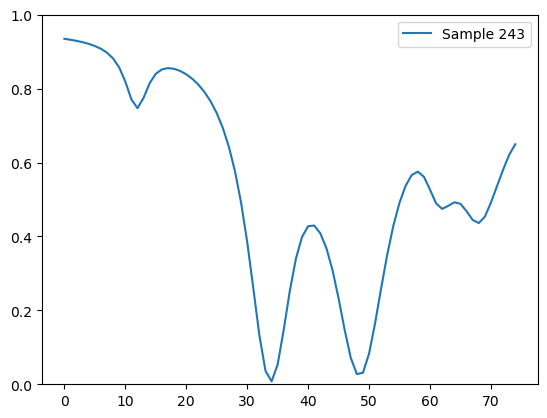


--- Physical Designs ---
[[0.64276356 1.5579304  0.86769444 0.6559822  1.5486264  0.27491036]
 [0.8710621  1.2313489  1.4221677  1.3926783  1.2467532  0.3342263 ]
 [0.66539174 0.87631404 0.9792415  1.2231019  1.0640315  0.66999364]
 [0.82530016 1.7981374  1.4802638  1.7380761  1.1635892  0.30723357]
 [0.62130666 0.48861274 1.382133   1.1251487  1.0130602  0.42644507]]
Saving predicted designs with full run ID: 12121438
Saving predicted designs with full inference ID: 1212170
Data saved in: geomerty_cVAE_reduced_range_2/inference_data/results/run_1212170


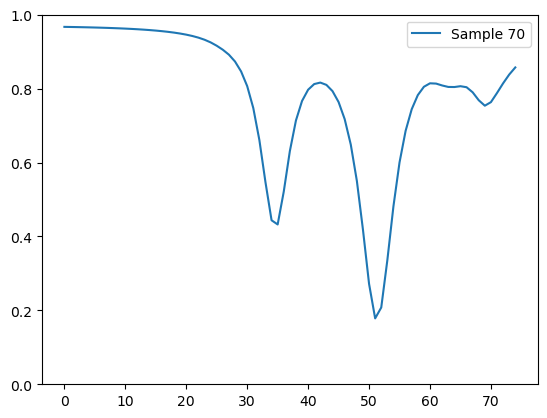


--- Physical Designs ---
[[0.7222417  1.6361421  1.040291   0.56426895 1.4088584  0.2533515 ]
 [0.9408575  1.2973403  1.57698    1.2977334  1.1086806  0.32018793]
 [0.7471876  0.95219326 1.1440098  1.1290203  0.91393363 0.6496682 ]
 [0.8985956  1.8619556  1.6426779  1.6481999  1.0313433  0.29503915]
 [0.6980103  0.56589    1.5349334  1.0176512  0.88098127 0.41154683]]
Saving predicted designs with full run ID: 12121438
Saving predicted designs with full inference ID: 12121413
Data saved in: geomerty_cVAE_reduced_range_2/inference_data/results/run_12121413


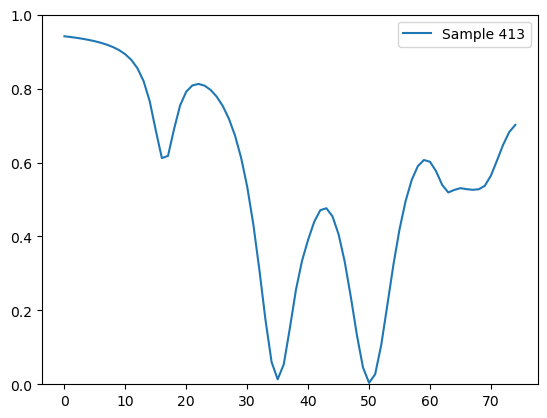


--- Physical Designs ---
[[0.6920455  1.5599246  1.1154822  0.60391194 1.3888953  0.2498609 ]
 [0.91573524 1.2232326  1.6544352  1.3419746  1.0801665  0.30935264]
 [0.7164022  0.87701607 1.2184321  1.1683542  0.88686794 0.6436093 ]
 [0.87157106 1.784624   1.7180073  1.6888456  0.992333   0.28513935]
 [0.67289627 0.49049637 1.5844694  1.0629681  0.8503222  0.39843675]]
Saving predicted designs with full run ID: 12121438
Saving predicted designs with full inference ID: 12121450
Data saved in: geomerty_cVAE_reduced_range_2/inference_data/results/run_12121450


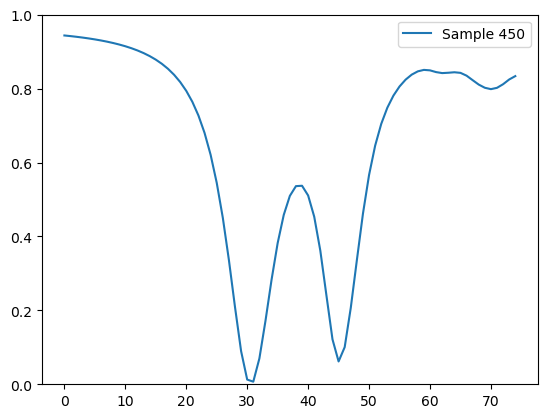

In [25]:
num_pred = 5

z_sample =  np.random.randn(num_pred, latent_dim)


for idx in samples:
    plt.plot(y_test[idx, :], label = f"Sample {idx}")

    target_spec = y_test[idx, :].numpy().flatten() if hasattr(y_test[idx, :], 'numpy') else y_test[idx, :].flatten()

    
    inference_id = int(f"12121{idx}")
    

    decoder_out = make_infrerence(decoder, z_sample, target_spec)


    decoder_out_physical = scaler_geo.inverse_transform(decoder_out)


    inference_parameters = {
    "latent_sampling_details": "np.random.randn(num_pred, latent_dim) ",
    "num_predictions": int(num_pred),
    "z_samples": z_sample.tolist(),
    }

    save_inference(
        inference_id=str(inference_id),
        inference_params=inference_parameters,
        inference_output=decoder_out.numpy() if hasattr(decoder_out, 'numpy') else decoder_out,
        target=target_spec,
        target_id=str(idx),
        wavelengths=wavelengths,
        scaler_geo=scaler_geo,
        base_dir=f"geomerty_cVAE_reduced_range_2/inference_data"
        )

    plt.ylim([0,1])
    plt.legend()
    plt.show()

In [26]:
import slurm_job_submitter
import time


cVAE_type = "geomerty"


for idx in samples:
    
    inference_id = f"12121{idx}"

    inference_data_folder = f"geomerty_cVAE_reduced_range_2/inference_data/results/run_{inference_id}" # os.path.join(f"{cVAE_type}_cVAE", f"inference_data/results/run_{inference_id}")

    local_param_file = os.path.join(inference_data_folder, f"{inference_id}_params.csv")

    remote_path = "/home/okcj1g19/micropillar_resim/" # Location on Iridis where files will be copied to

    job_script = "js_micropillar_resim_dis.sh"

    slurm_job_submitter.run_submission(inference_id, local_param_file, remote_path, job_script)#
    
    time.sleep(1)

--> Starting file transfer to okcj1g19@iridis6.soton.ac.uk:/home/okcj1g19/micropillar_resim/...
--> File transfer successful.
--> Submitting job: /home/okcj1g19/micropillar_resim/js_micropillar_resim_dis.sh...
--> Job submission successful.
    Server response: Submitted batch job 2453627

Process completed successfully!
--> Starting file transfer to okcj1g19@iridis6.soton.ac.uk:/home/okcj1g19/micropillar_resim/...
--> File transfer successful.
--> Submitting job: /home/okcj1g19/micropillar_resim/js_micropillar_resim_dis.sh...
--> Job submission successful.
    Server response: Submitted batch job 2453628

Process completed successfully!
--> Starting file transfer to okcj1g19@iridis6.soton.ac.uk:/home/okcj1g19/micropillar_resim/...
--> File transfer successful.
--> Submitting job: /home/okcj1g19/micropillar_resim/js_micropillar_resim_dis.sh...
--> Job submission successful.
    Server response: Submitted batch job 2453629

Process completed successfully!
--> Starting file transfer to o

single axis
0.803, 1.139, 1.109, 0.717
0.909, 1.379, 1.144, 0.780
0.915, 1.206, 0.911, 0.971
0.927, 1.445, 1.136, 1.313
0.940, 1.312, 1.122, 1.168


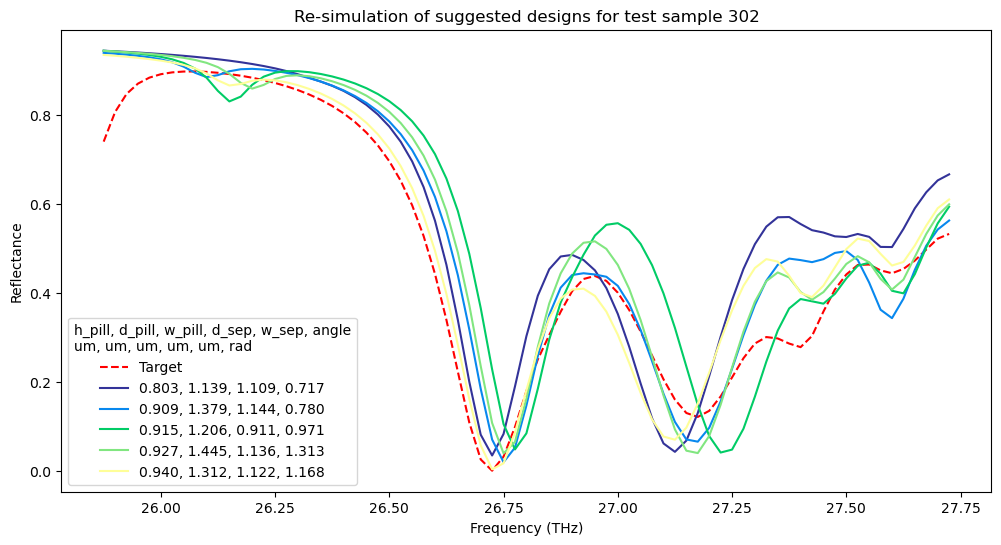

single axis
0.563, 0.752, 1.524, 1.083
0.657, 1.008, 1.574, 1.163
0.661, 0.854, 1.338, 1.318
0.677, 1.093, 1.574, 1.701
0.687, 0.947, 1.575, 1.541


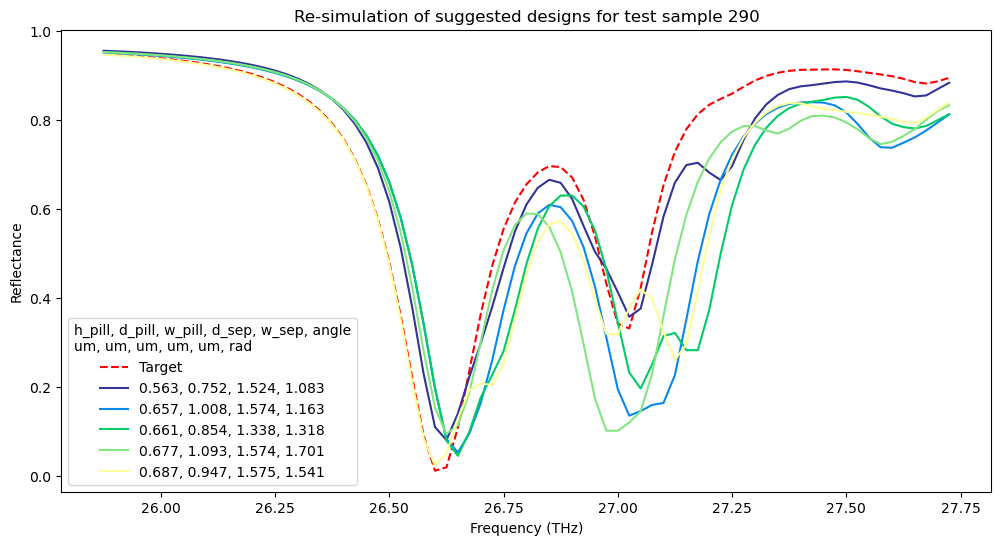

single axis
0.603, 1.199, 1.512, 0.911
0.713, 1.452, 1.549, 0.954
0.715, 1.291, 1.296, 1.134
0.724, 1.528, 1.528, 1.467
0.745, 1.393, 1.513, 1.338


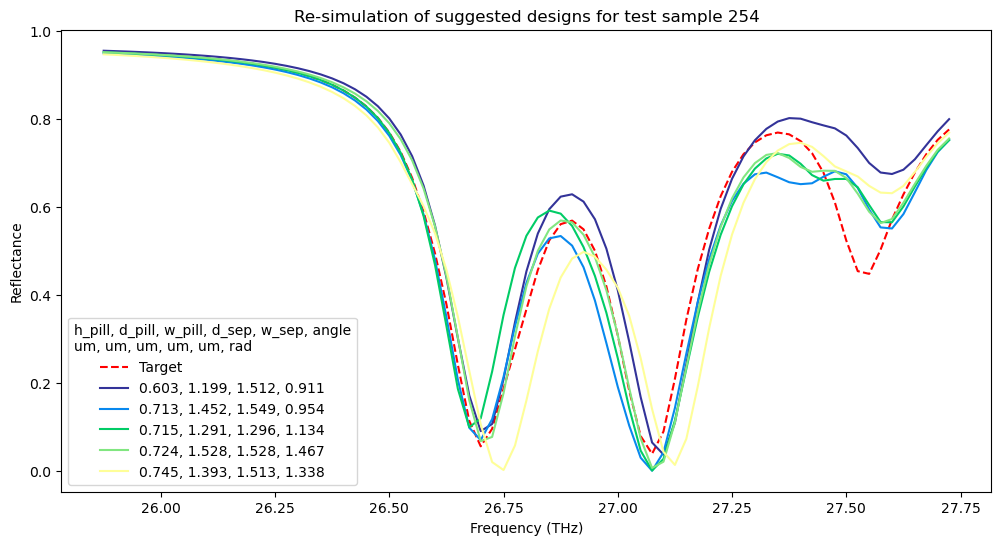

single axis
0.540, 1.090, 1.173, 1.035
0.636, 1.307, 1.206, 1.091
0.639, 1.141, 0.986, 1.268
0.651, 1.379, 1.193, 1.600
0.667, 1.231, 1.181, 1.486


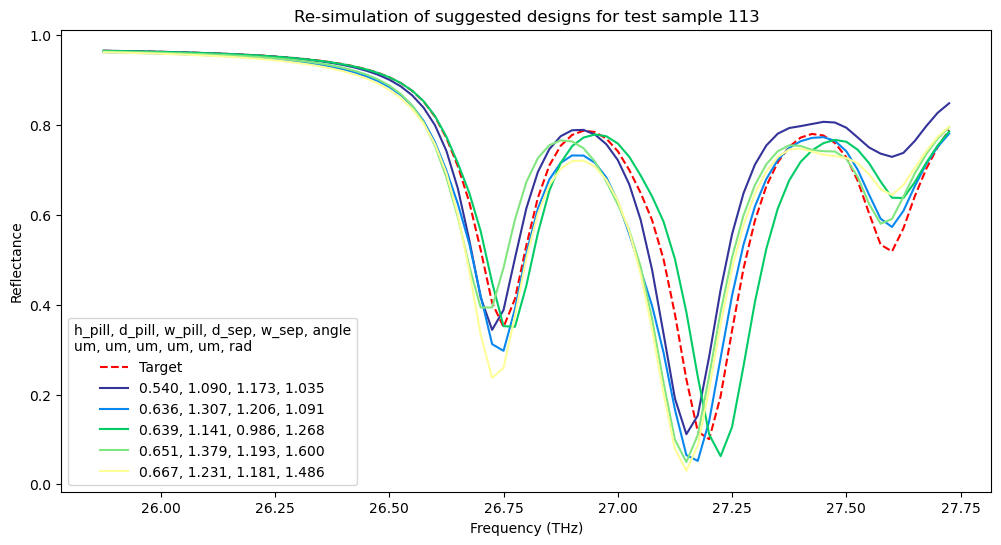

single axis
0.596, 1.189, 1.530, 0.911
0.706, 1.460, 1.563, 0.943
0.707, 1.276, 1.316, 1.128
0.720, 1.534, 1.533, 1.457
0.738, 1.391, 1.506, 1.331


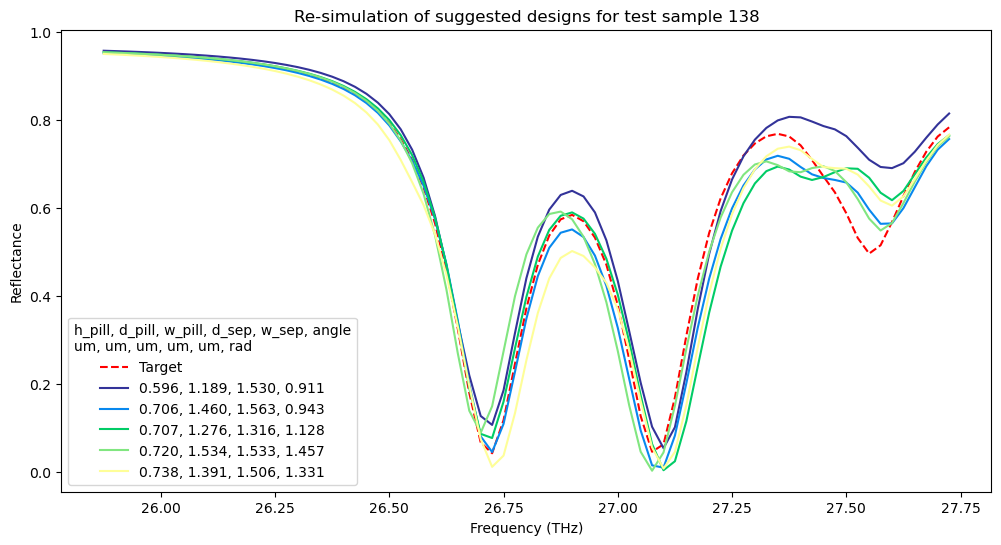

single axis
0.826, 1.107, 1.604, 0.649
0.928, 1.399, 1.648, 0.692
0.928, 1.212, 1.393, 0.900
0.936, 1.460, 1.641, 1.255
0.951, 1.344, 1.609, 1.141


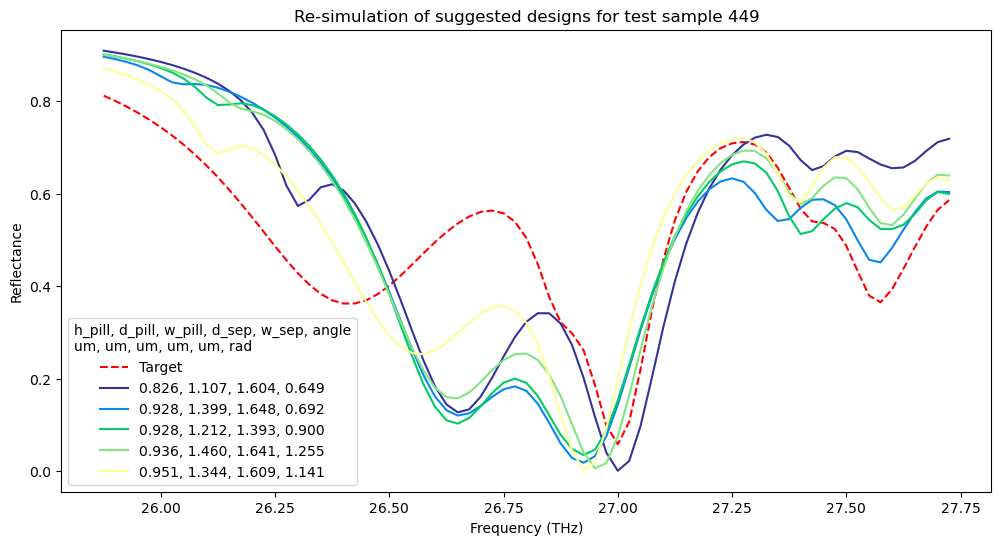

single axis
0.587, 0.965, 1.407, 0.978
0.685, 1.015, 1.189, 1.245
0.685, 1.218, 1.451, 1.063
0.704, 1.303, 1.406, 1.584
0.716, 1.149, 1.394, 1.451


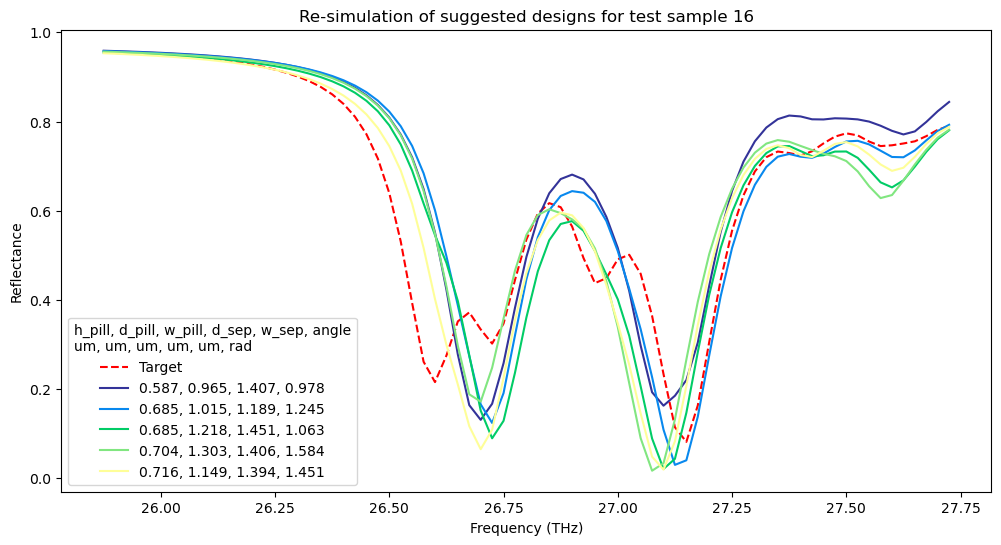

single axis
0.684, 1.065, 1.128, 0.795
0.780, 1.315, 1.169, 0.865
0.781, 1.142, 0.942, 1.059
0.794, 1.380, 1.150, 1.389
0.810, 1.247, 1.144, 1.262


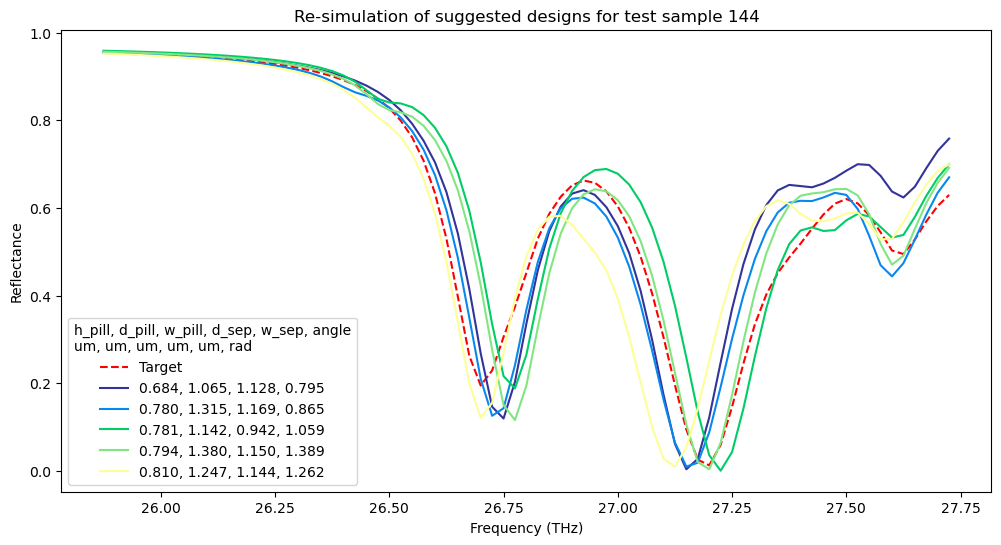

single axis
0.767, 1.340, 1.254, 0.717
0.862, 1.561, 1.306, 0.747
0.862, 1.409, 1.049, 0.950
0.875, 1.627, 1.275, 1.229
0.889, 1.495, 1.268, 1.121


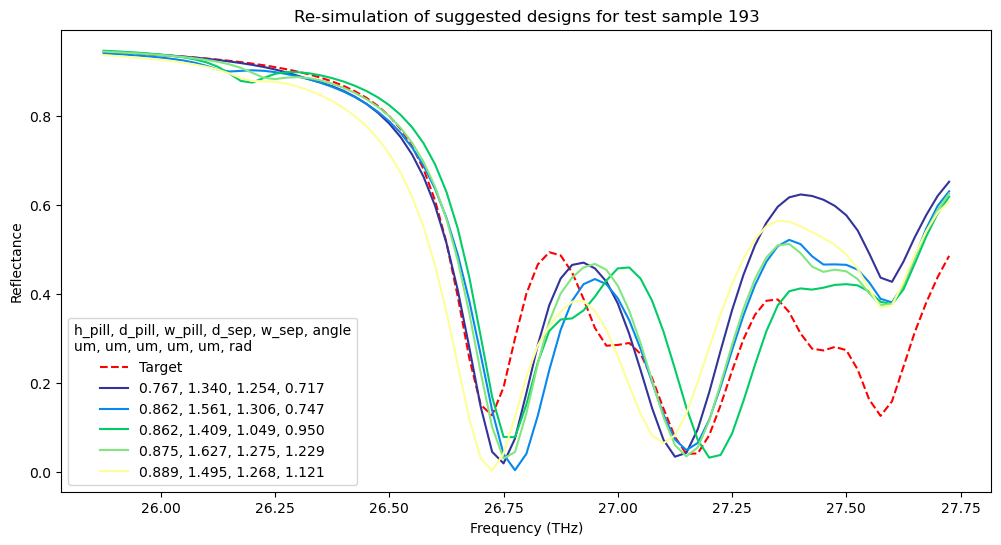

In [33]:
from helper import read_comsol_csv, plot_comsol

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path


for idx in samples:
    
    ID = f"10101{idx}"


    fig, axes = plt.subplots(1, 1, figsize=(12, 6))


    # ID = "7"

    run_folder = f"geomerty_cVAE_reduced_range/inference_data/results/run_{ID}/"

    # df = read_comsol_csv(run_folder / "micro_pillar_resim.csv")
    
    try:
        df = read_comsol_csv(run_folder + (ID + "_dataout.csv"))

    except FileNotFoundError:
        print(f"File not found for ID: {ID}")
        continue

    target = np.loadtxt(run_folder + (ID + "_target_spectra.csv"), delimiter=",")

    axes.plot(target[:, 0], target[:, 1], label = "Target", linestyle='--', color='red')

    plot_comsol(
        df,
        axes,
        ["Reflection (1)"], # ["abs(emw.S11)^2 (1)"], #
        xdata_indx=6,
        resim=True
    )

    # axes.set_title("Re-simulation of test dataset sample")
    axes.set_title("Re-simulation of suggested designs for test sample " + str(idx))
    axes.set_xlabel("Frequency (THz)")
    axes.set_ylabel("Reflectance")
    axes.legend(title="h_pill, d_pill, w_pill, d_sep, w_sep, angle\num, um, um, um, um, rad")
    #plt.savefig(run_folder / "testdata_micro_pillar_resim.png", dpi=300)
    plt.savefig(run_folder + ID + "_test_index_resim.png", dpi=300)
    plt.show()

single axis
0.621, 0.489, 1.382, 1.125
0.643, 1.558, 0.868, 0.656
0.665, 0.876, 0.979, 1.223
0.825, 1.798, 1.480, 1.738
0.871, 1.231, 1.422, 1.393


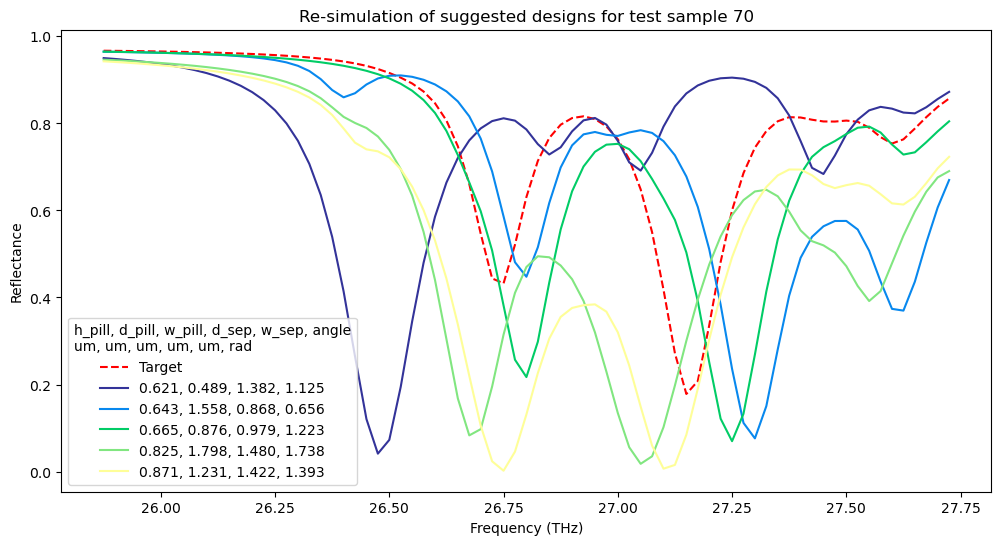

single axis
0.673, 0.490, 1.584, 1.063
0.692, 1.560, 1.115, 0.604
0.716, 0.877, 1.218, 1.168
0.872, 1.785, 1.718, 1.689
0.916, 1.223, 1.654, 1.342


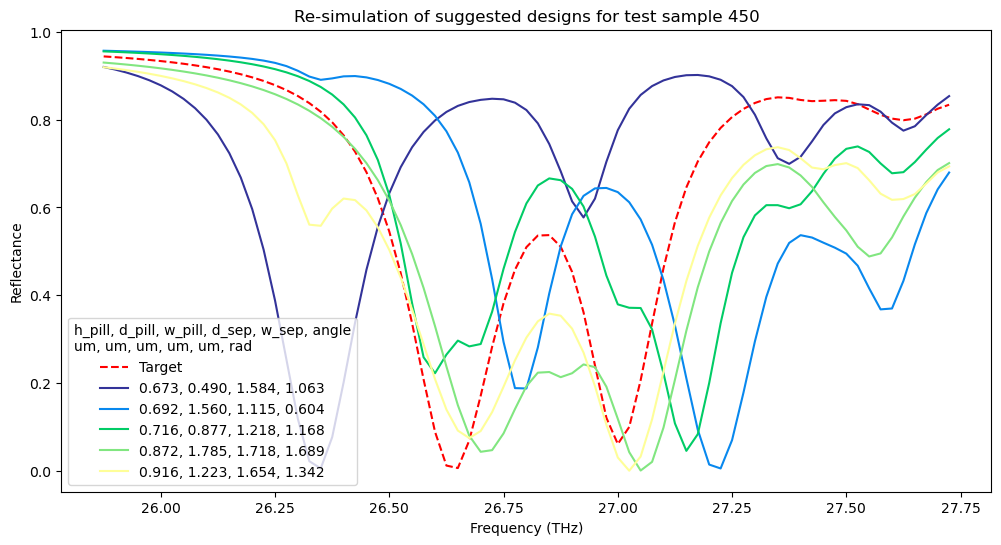

single axis
0.637, 0.529, 1.349, 1.094
0.660, 1.607, 0.826, 0.633
0.684, 0.919, 0.925, 1.196
0.842, 1.843, 1.424, 1.711
0.888, 1.276, 1.366, 1.361


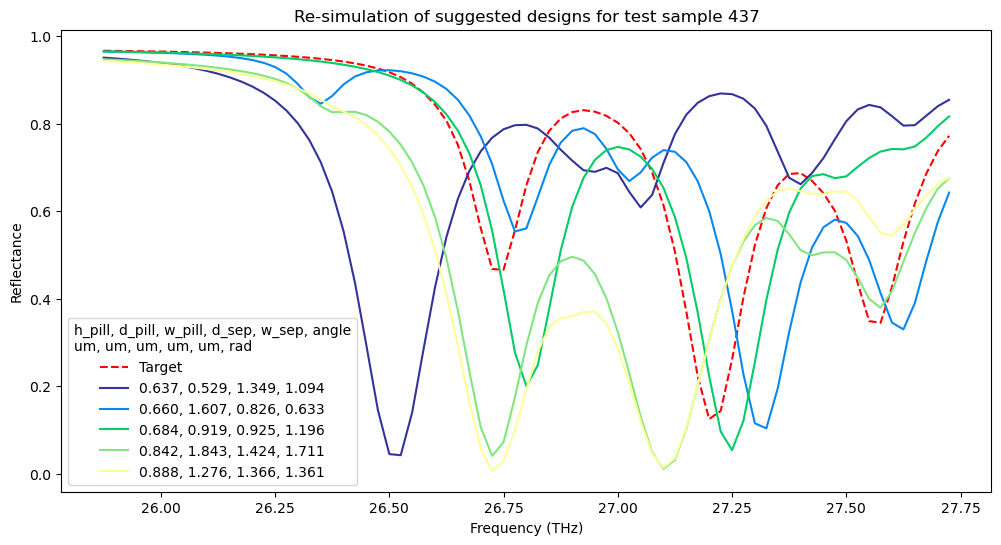

single axis
0.698, 0.566, 1.535, 1.018
0.722, 1.636, 1.040, 0.564
0.747, 0.952, 1.144, 1.129
0.899, 1.862, 1.643, 1.648
0.941, 1.297, 1.577, 1.298


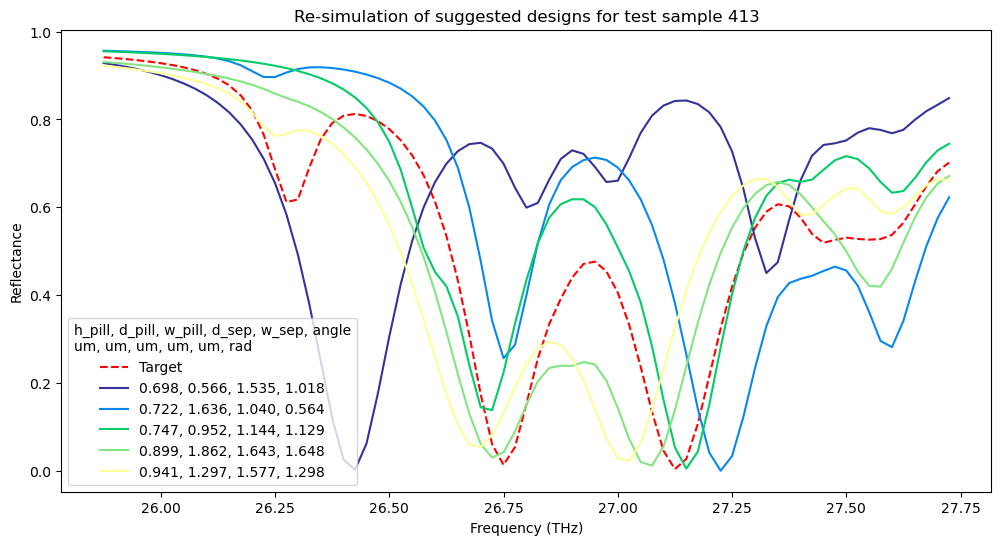

single axis
0.667, 0.534, 1.418, 1.064
0.689, 1.611, 0.903, 0.601
0.713, 0.924, 1.009, 1.166
0.868, 1.842, 1.505, 1.686
0.912, 1.275, 1.443, 1.334


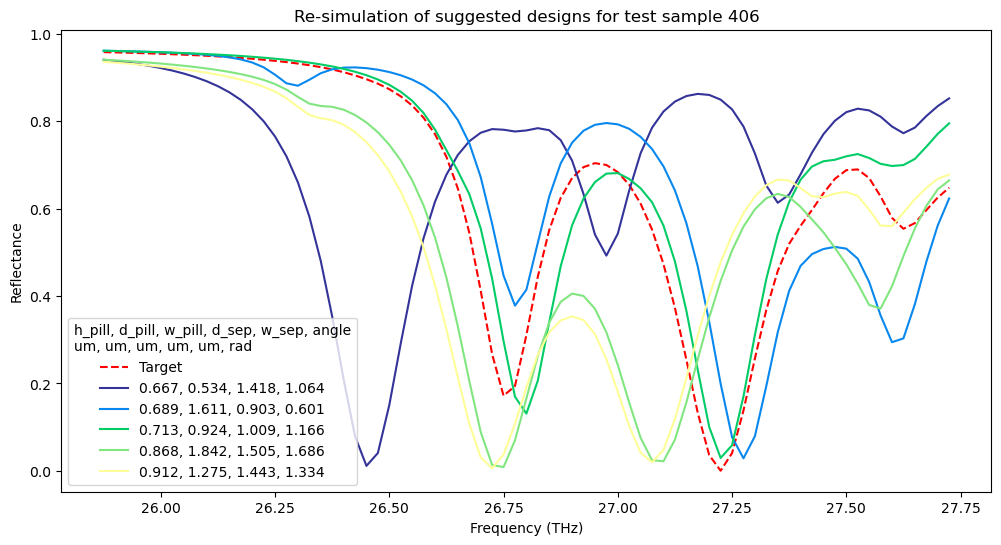

single axis
0.698, 0.563, 1.571, 1.023
0.722, 1.628, 1.090, 0.574
0.747, 0.946, 1.190, 1.137
0.898, 1.849, 1.688, 1.654
0.939, 1.288, 1.623, 1.304


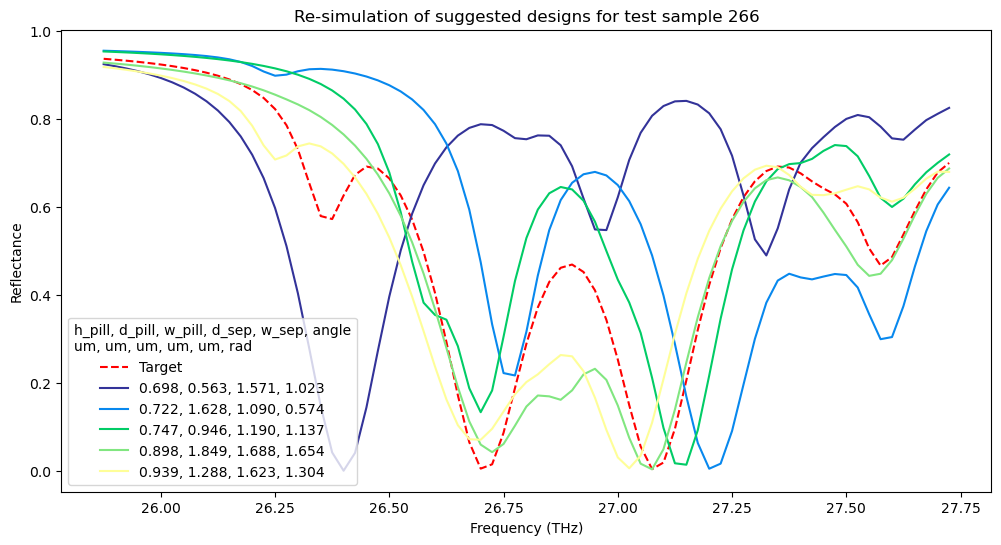

single axis
0.707, 0.587, 1.548, 1.000
0.734, 1.652, 1.059, 0.552
0.758, 0.971, 1.161, 1.114
0.909, 1.876, 1.659, 1.632
0.950, 1.315, 1.594, 1.281


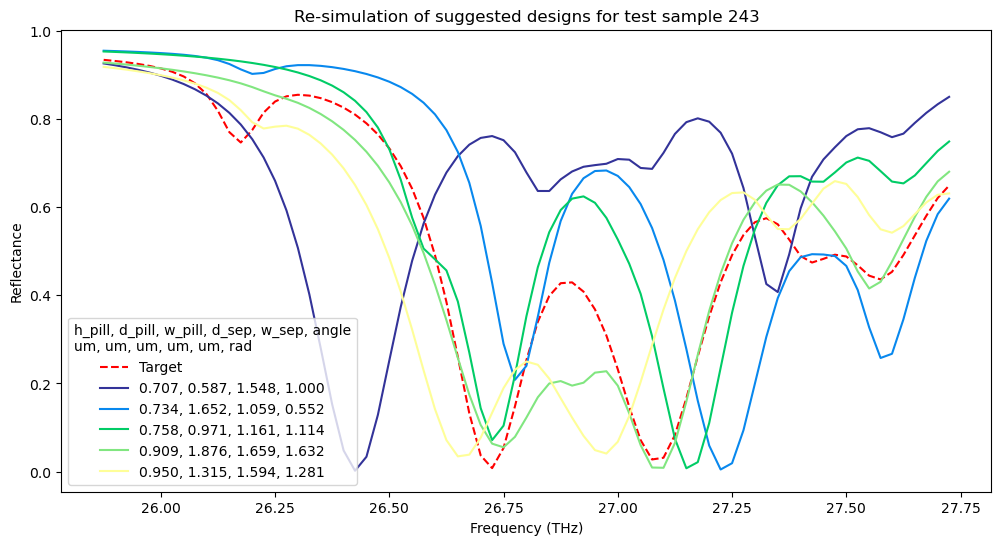

single axis
0.708, 0.600, 1.445, 0.989
0.737, 1.671, 0.931, 0.542
0.761, 0.983, 1.044, 1.100
0.913, 1.899, 1.535, 1.620
0.954, 1.335, 1.476, 1.262


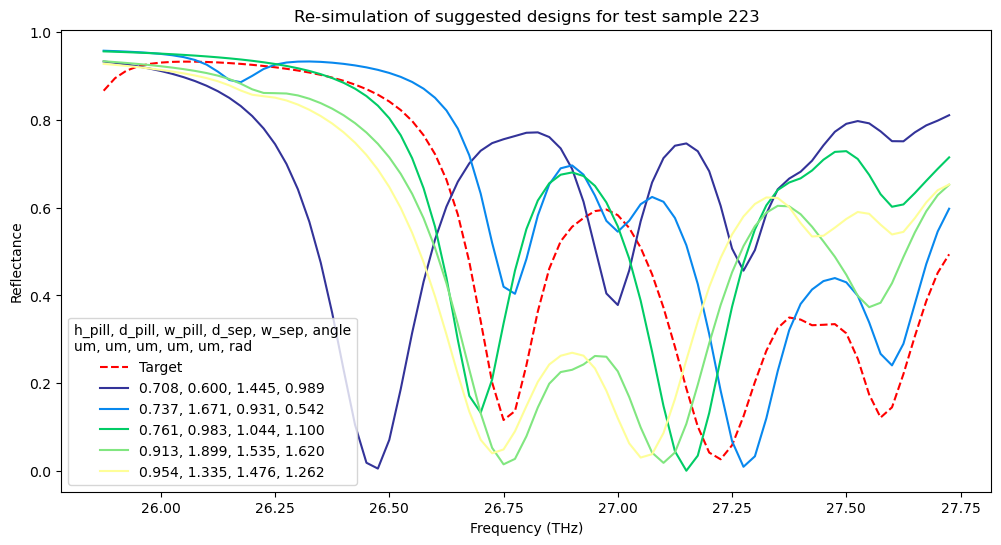

single axis
0.706, 0.456, 1.656, 1.037
0.726, 1.554, 1.155, 0.579
0.751, 0.843, 1.285, 1.140
0.908, 1.776, 1.800, 1.670
0.950, 1.185, 1.743, 1.317


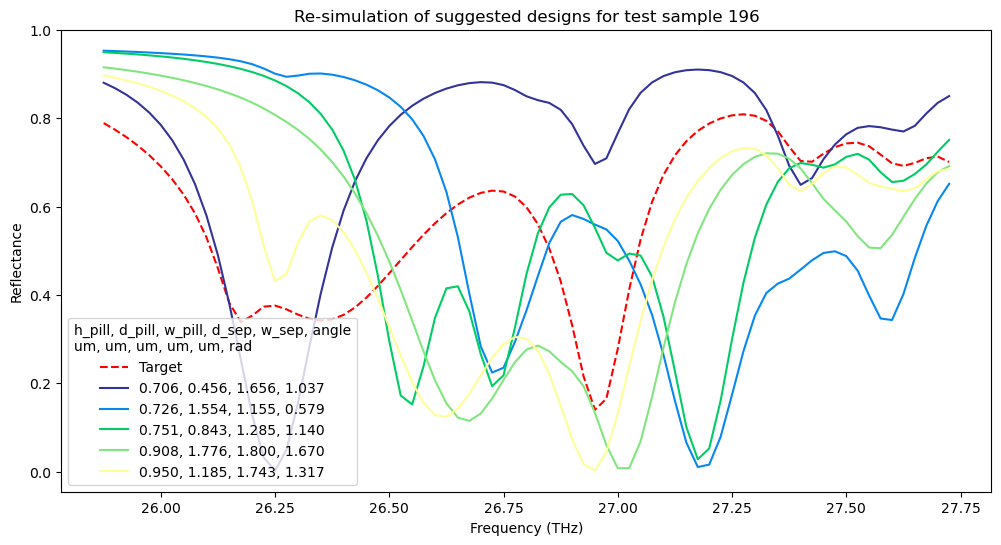

In [3]:
from helper import read_comsol_csv, plot_comsol

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

samples = [70, 450, 437, 413, 406, 266, 243, 223, 196]

for idx in samples:
    
    ID = f"12121{idx}"


    fig, axes = plt.subplots(1, 1, figsize=(12, 6))


    # ID = "7"

    run_folder = f"geomerty_cVAE_reduced_range_2/inference_data/results/run_{ID}/"

    # df = read_comsol_csv(run_folder / "micro_pillar_resim.csv")
    
    try:
        df = read_comsol_csv(run_folder + (ID + "_dataout.csv"))

    except FileNotFoundError:
        print(f"File not found for ID: {ID}")
        continue

    target = np.loadtxt(run_folder + (ID + "_target_spectra.csv"), delimiter=",")

    axes.plot(target[:, 0], target[:, 1], label = "Target", linestyle='--', color='red')

    plot_comsol(
        df,
        axes,
        ["Reflection (1)"], # ["abs(emw.S11)^2 (1)"], #
        xdata_indx=6,
        resim=True
    )

    # axes.set_title("Re-simulation of test dataset sample")
    axes.set_title("Re-simulation of suggested designs for test sample " + str(idx))
    axes.set_xlabel("Frequency (THz)")
    axes.set_ylabel("Reflectance")
    axes.legend(title="h_pill, d_pill, w_pill, d_sep, w_sep, angle\num, um, um, um, um, rad")
    #plt.savefig(run_folder / "testdata_micro_pillar_resim.png", dpi=300)
    plt.savefig(run_folder + ID + "_test_index_resim.png", dpi=300)
    plt.show()